In [2]:
# ==============================================================================
# Project 2: Histopathology & Cell Morphology Analytics Pipeline
# Author: Ron Bar
# Focus: Histology, Medical Laboratory Science & Clinical ML
# Tech Stack: Python, Scikit-Learn, Pandas, NumPy, Seaborn, Matplotlib
#
# Executive Summary:
# This project processes a benchmark clinical histopathology dataset comprising
# 569 digitized fine needle aspirate (FNA) biopsy samples. It extracts 30
# morphological cellular features with clinical micrometer units (e.g., radius in µm, area in µm²)
# to classify tissue samples into Benign or Malignant pathology grades.
# ==============================================================================

import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1. Load Real Clinical Histopathology Dataset
cancer_data = load_breast_cancer()

# 2. Construct Structured DataFrame
df_histo = pd.DataFrame(data=cancer_data.data, columns=cancer_data.feature_names)
df_histo['pathology_class'] = cancer_data.target
df_histo['pathology_label'] = df_histo['pathology_class'].map({0: 'Malignant', 1: 'Benign'})

# 3. Rename key morphology columns with clinical units (µm, µm²)
df_histo.rename(columns={
    'mean radius': 'nucleus_radius_mean_um',
    'mean texture': 'nucleus_texture_gray_sd',
    'mean perimeter': 'nucleus_perimeter_mean_um',
    'mean area': 'nucleus_area_mean_sq_um',
    'mean concavity': 'nucleus_concavity_score'
}, inplace=True)

print("✅ Clinical Histopathology Dataset Loaded Successfully!")
print(f"Dataset Dimensions: {df_histo.shape[0]} Biopsy Samples | {df_histo.shape[1]} Clinical Features\n")

# 4. Clinical Aggregation Summary by Pathology Grade
summary_metrics = [
    'nucleus_radius_mean_um',
    'nucleus_texture_gray_sd',
    'nucleus_area_mean_sq_um',
    'nucleus_concavity_score'
]
clinical_summary = df_histo.groupby('pathology_label')[summary_metrics].mean().round(3)

print("--- Clinical Morphology Mean Breakdown (Units: µm, µm², Intensity SD) ---")
display(clinical_summary)

✅ Clinical Histopathology Dataset Loaded Successfully!
Dataset Dimensions: 569 Biopsy Samples | 32 Clinical Features

--- Clinical Morphology Mean Breakdown (Units: µm, µm², Intensity SD) ---


,nucleus_radius_mean_um,nucleus_texture_gray_sd,nucleus_area_mean_sq_um,nucleus_concavity_score
pathology_label,,,,
Benign,12.147,17.915,462.790,0.046
Malignant,17.463,21.605,978.376,0.161


/tmp/ipykernel_3605/1591256135.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3605/1591256135.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


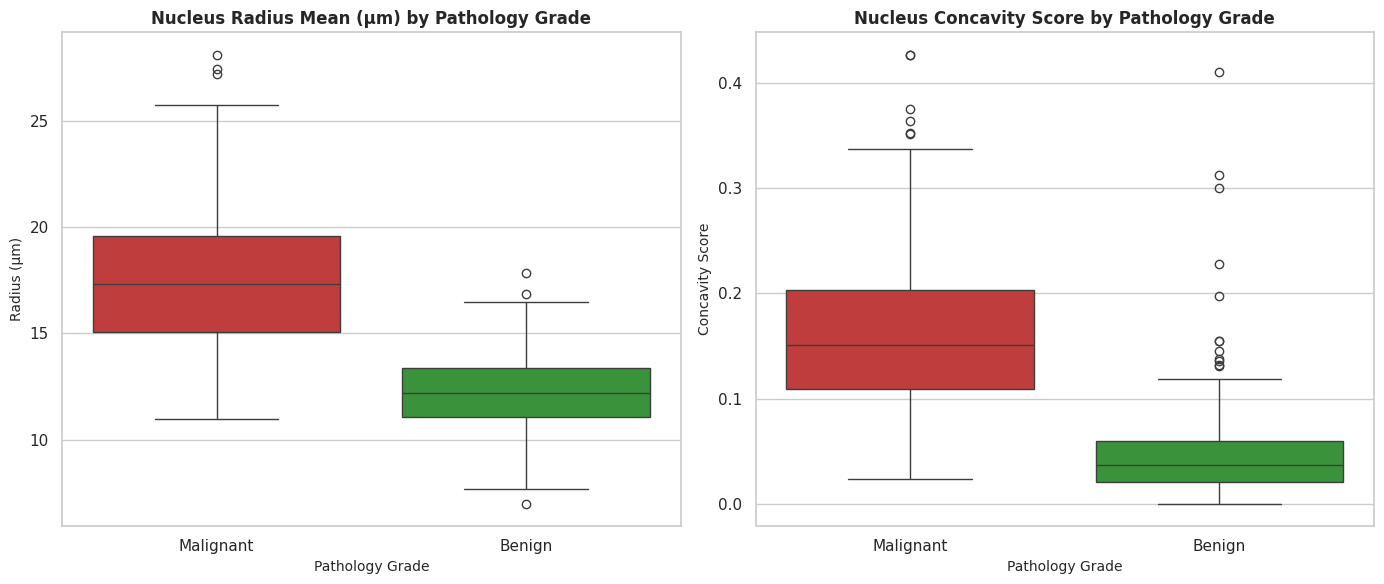

✅ Clinical morphology visualization generated and saved successfully!


In [3]:
# ==============================================================================
# Step 2: Clinical Morphology Visualization & Exploratory Data Analysis (EDA)
# ==============================================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Set style for clinical visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# 1. Boxplot: Nucleus Radius Mean (µm) across Pathology Classes
plt.subplot(1, 2, 1)
sns.boxplot(
    data=df_histo,
    x='pathology_label',
    y='nucleus_radius_mean_um',
    palette={'Malignant': '#d62728', 'Benign': '#2ca02c'}
)
plt.title('Nucleus Radius Mean (µm) by Pathology Grade', fontsize=12, fontweight='bold')
plt.xlabel('Pathology Grade', fontsize=10)
plt.ylabel('Radius (µm)', fontsize=10)

# 2. Boxplot: Nucleus Concavity Score across Pathology Classes
plt.subplot(1, 2, 2)
sns.boxplot(
    data=df_histo,
    x='pathology_label',
    y='nucleus_concavity_score',
    palette={'Malignant': '#d62728', 'Benign': '#2ca02c'}
)
plt.title('Nucleus Concavity Score by Pathology Grade', fontsize=12, fontweight='bold')
plt.xlabel('Pathology Grade', fontsize=10)
plt.ylabel('Concavity Score', fontsize=10)

plt.tight_layout()
plt.savefig("clinical_morphology_distribution.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Clinical morphology visualization generated and saved successfully!")

✅ Random Forest Model Trained Successfully!
🎯 Clinical ROC-AUC Score: 0.9934

--- Clinical Classification Report ---
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



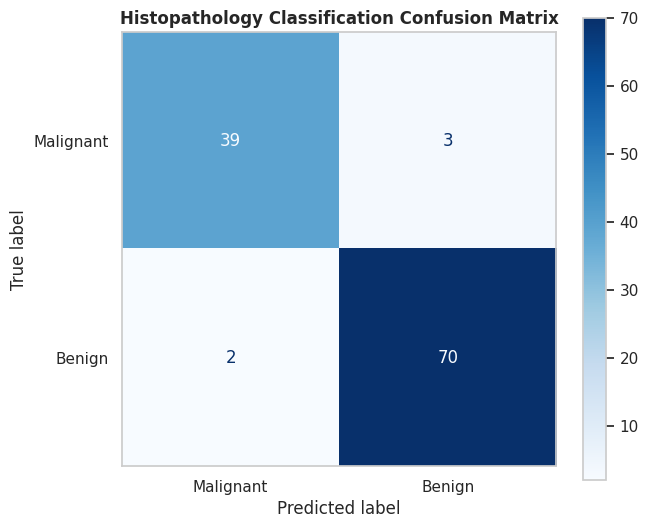

In [4]:
# ==============================================================================
# Step 3: Machine Learning Classification & Clinical Performance Evaluation
# ==============================================================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Separate Features (X) and Target Label (y)
X = df_histo.drop(columns=['pathology_class', 'pathology_label'])
y = df_histo['pathology_class']  # 0: Malignant, 1: Benign

# 2. Train-Test Split (80% Train, 20% Test) with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Initialize & Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Predictions & Evaluation
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("✅ Random Forest Model Trained Successfully!")
print(f"🎯 Clinical ROC-AUC Score: {roc_auc:.4f}\n")
print("--- Clinical Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

# 5. Visualize & Save Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Malignant', 'Benign'],
    cmap='Blues',
    ax=ax
)
plt.title("Histopathology Classification Confusion Matrix", fontsize=12, fontweight='bold')
plt.grid(False)
plt.savefig("clinical_model_evaluation.png", dpi=300, bbox_inches='tight')
plt.show()

--- Top 10 Clinical Morphological Predictors ---


,Feature,Importance
23,worst area,0.138294
27,worst concave points,0.132993
20,worst radius,0.100805
7,mean concave points,0.098489
22,worst perimeter,0.072224
2,nucleus_perimeter_mean_um,0.068612
0,nucleus_radius_mean_um,0.067465
6,nucleus_concavity_score,0.057445
3,nucleus_area_mean_sq_um,0.050615
26,worst concavity,0.031544


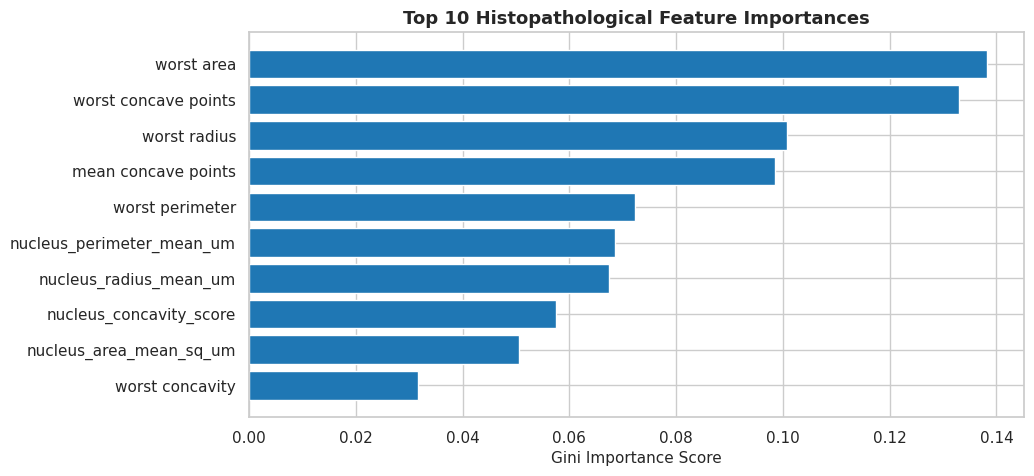


--- Real-Time Clinical Inference Test ---
Predicted Pathology Grade: Malignant
Diagnostic Model Confidence: 99.96%


In [5]:
# ==============================================================================
# Step 4: Morphological Feature Importance & Clinical Inference Simulation
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract Top 10 Morphological Features by Gini Importance
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

top_10_features = feature_importances.head(10)

print("--- Top 10 Clinical Morphological Predictors ---")
display(top_10_features)

# 2. Visualize Top Feature Importances
plt.figure(figsize=(10, 5))
plt.barh(top_10_features['Feature'], top_10_features['Importance'], color='#1f77b4')
plt.xlabel("Gini Importance Score", fontsize=11)
plt.title("Top 10 Histopathological Feature Importances", fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
plt.savefig("clinical_feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()

# 3. Clinical Inference Engine Function
def predict_biopsy_pathology(sample_features):
    """
    Simulates real-time clinical decision support using 30 cytometric features.
    """
    input_data = pd.DataFrame([sample_features], columns=X.columns)

    prediction_class = rf_model.predict(input_data)[0]
    prediction_label = 'Benign' if prediction_class == 1 else 'Malignant'
    confidence = np.max(rf_model.predict_proba(input_data)[0]) * 100

    return prediction_label, confidence

# Test with a single test sample from the dataset
sample_biopsy = X_test.iloc[0].values
pathology_res, confidence_res = predict_biopsy_pathology(sample_biopsy)

print("\n--- Real-Time Clinical Inference Test ---")
print(f"Predicted Pathology Grade: {pathology_res}")
print(f"Diagnostic Model Confidence: {confidence_res:.2f}%")